<a href="https://colab.research.google.com/github/Aditigk1203/ADITI-G-KRISHNAN/blob/main/Phase1_Stars_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ADITI KRISHNAN

23BDS0054

PHASE 1 PROJECT - EDA

DATASET - https://raw.githubusercontent.com/salemprakash/EDA/main/Data/stars%20type.csv


# STEP 1 : Loading the dataset


In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# loading dataset
df = pd.read_csv("stars_type.csv")
df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.0024,0.1700,16.12,0,Red,M
1,3042,0.0005,0.1542,16.60,0,Red,M
2,2600,0.0003,0.1020,18.70,0,Red,M
3,2800,0.0002,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


# STEP 2 : Applying basic statistical analysis


In [2]:
# dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    object 
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              237 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(2), int64(2), object(3)
memory usage: 13.3+ KB


In [3]:
# rows col count
df.shape

(240, 7)

In [4]:
# cols names

df.columns

Index(['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)',
       'Absolute magnitude(Mv)', 'Star type', 'Star color', 'Spectral Class'],
      dtype='object')

In [5]:
# data type of cols
df.dtypes

,0
Temperature (K),int64
Luminosity(L/Lo),object
Radius(R/Ro),float64
Absolute magnitude(Mv),float64
Star type,int64
Star color,object
Spectral Class,object


In [6]:
# statistical info
df.describe(include='all')

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
count,240.000000,240,240.000000,240.000000,240.000000,237,240
unique,NaN,208,NaN,NaN,NaN,19,8
top,NaN,200000,NaN,NaN,NaN,Red,M
freq,NaN,5,NaN,NaN,NaN,110,108
mean,10497.462500,NaN,237.157781,4.382396,2.500000,NaN,NaN
std,9552.425037,NaN,517.155763,10.532512,1.711394,NaN,NaN
min,1939.000000,NaN,0.008400,-11.920000,0.000000,NaN,NaN
25%,3344.250000,NaN,0.102750,-6.232500,1.000000,NaN,NaN
50%,5776.000000,NaN,0.762500,8.313000,2.500000,NaN,NaN
75%,15055.500000,NaN,42.750000,13.697500,4.000000,NaN,NaN


# STEP 3 : Handling missing data


In [7]:
# checking values

df.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,3
Spectral Class,0


In [8]:
# percentage

(df.isnull().sum()/len(df))*100

,0
Temperature (K),0.00
Luminosity(L/Lo),0.00
Radius(R/Ro),0.00
Absolute magnitude(Mv),0.00
Star type,0.00
Star color,1.25
Spectral Class,0.00


In [9]:
# fill using mode

df['Star color'].fillna(df['Star color'].mode()[0], inplace=True)

/tmp/ipykernel_5461/3646810259.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Star color'].fillna(df['Star color'].mode()[0], inplace=True)


In [10]:
# verify

df.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,0
Spectral Class,0


# STEP 4 Data cleaning



In [11]:
# duplicate checkd
df.duplicated().sum()
#no dup

np.int64(0)

In [12]:
df.dtypes

,0
Temperature (K),int64
Luminosity(L/Lo),object
Radius(R/Ro),float64
Absolute magnitude(Mv),float64
Star type,int64
Star color,object
Spectral Class,object


# STEP 5 Data transformation

In [13]:
df.columns

Index(['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)',
       'Absolute magnitude(Mv)', 'Star type', 'Star color', 'Spectral Class'],
      dtype='object')

In [14]:
df.rename(columns={
    'Temperature (K)': 'Temperature',
    'Luminosity(L/Lo)': 'Luminosity',
    'Radius(R/Ro)': 'Radius',
    'Absolute magnitude(Mv)': 'Absolute_Magnitude',
    'Star color': 'Star_Color',
    'Spectral Class': 'Spectral_Class',
    'Star type': 'Star_Type'
}, inplace=True)

In [15]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Star_Color'] = le.fit_transform(df['Star_Color'])
df['Spectral_Class'] = le.fit_transform(df['Spectral_Class'])

In [19]:
df['Luminosity'] = pd.to_numeric(df['Luminosity'], errors='coerce')

In [23]:
df['Luminosity'] = df['Luminosity'].fillna(df['Luminosity'].median())

In [24]:
df.tail()

,Temperature,Luminosity,Radius,Absolute_Magnitude,Star_Type,Star_Color,Spectral_Class
235,38940,374830.0,1356.0,-9.93,5,0,7
236,30839,834042.0,1194.0,-10.63,5,0,7
237,8829,537493.0,1423.0,-10.73,5,11,1
238,9235,404940.0,1112.0,-11.23,5,11,1
239,37882,294903.0,1783.0,-7.80,5,0,7


In [25]:
df.isnull().sum()

,0
Temperature,0
Luminosity,0
Radius,0
Absolute_Magnitude,0
Star_Type,0
Star_Color,0
Spectral_Class,0


In [26]:
df.corr(numeric_only=True)

,Temperature,Luminosity,Radius,Absolute_Magnitude,Star_Type,Star_Color,Spectral_Class
Temperature,1.000000,0.374901,0.064216,-0.420261,0.411129,-0.692832,-0.174169
Luminosity,0.374901,1.000000,0.530908,-0.686880,0.671791,-0.378480,0.280427
Radius,0.064216,0.530908,1.000000,-0.608728,0.660975,-0.003973,0.110408
Absolute_Magnitude,-0.420261,-0.686880,-0.608728,1.000000,-0.955276,0.325286,-0.120811
Star_Type,0.411129,0.671791,0.660975,-0.955276,1.000000,-0.310879,-0.003410
Star_Color,-0.692832,-0.378480,-0.003973,0.325286,-0.310879,1.000000,-0.016581
Spectral_Class,-0.174169,0.280427,0.110408,-0.120811,-0.003410,-0.016581,1.000000


#STEP 6 Univariate Analysis

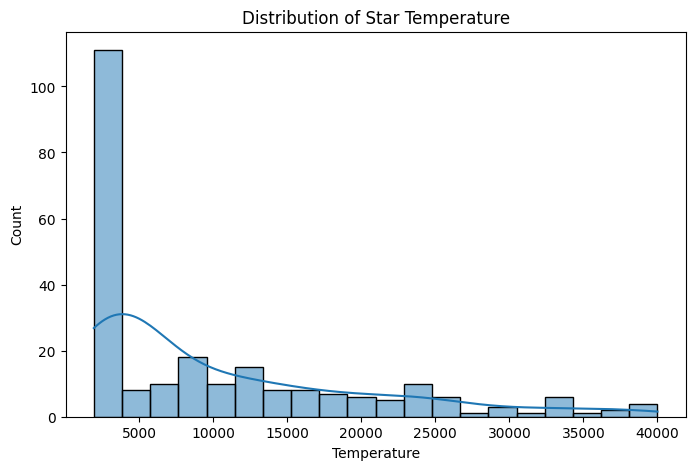

In [27]:
#Histogram
plt.figure(figsize=(8,5))
sns.histplot(df['Temperature'], bins=20, kde=True)
plt.title("Distribution of Star Temperature")
plt.xlabel("Temperature")
plt.ylabel("Count")
plt.show()


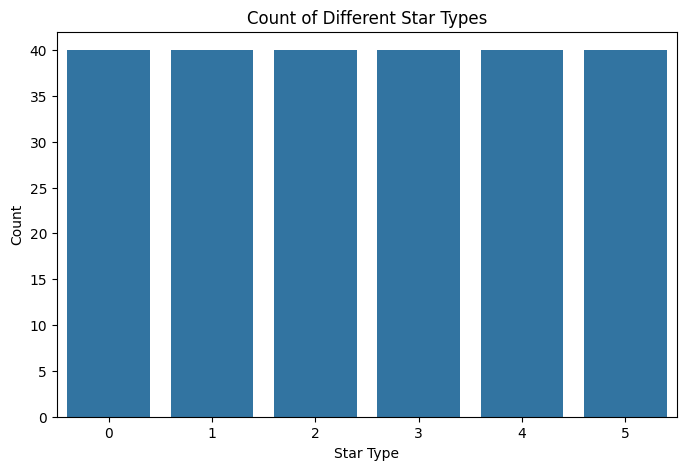

In [28]:
#Count Plot:
plt.figure(figsize=(8,5))
sns.countplot(x='Star_Type', data=df)
plt.title("Count of Different Star Types")
plt.xlabel("Star Type")
plt.ylabel("Count")
plt.show()

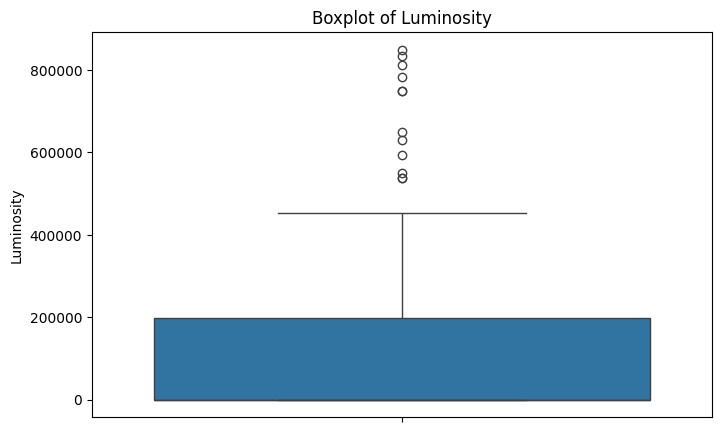

In [29]:
#Box Plot
plt.figure(figsize=(8,5))
sns.boxplot(y=df['Luminosity'])
plt.title("Boxplot of Luminosity")
plt.ylabel("Luminosity")
plt.show()

# STEP 7 Bivariate Analysis

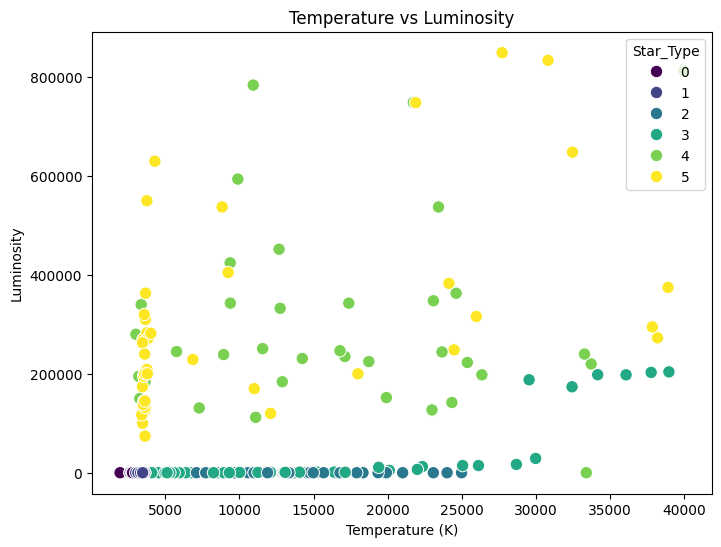

In [30]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='Temperature',
    y='Luminosity',
    hue='Star_Type',
    palette='viridis',
    s=80
)

plt.title("Temperature vs Luminosity")
plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity")
plt.show()

/tmp/ipykernel_5461/2855270224.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


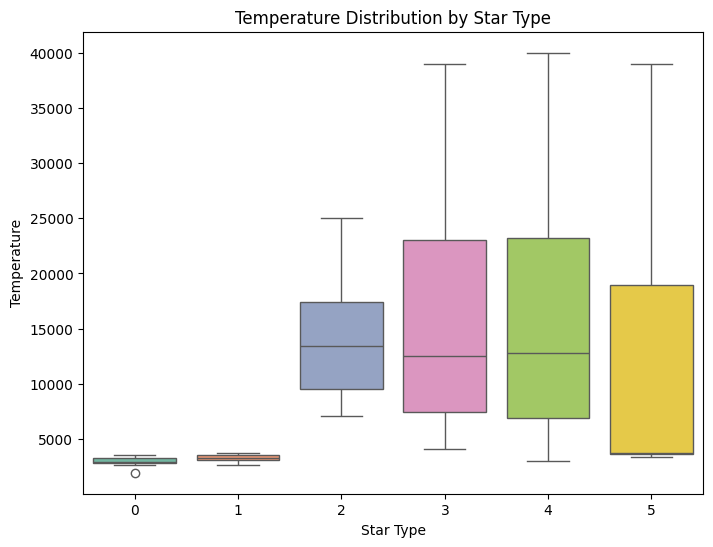

In [31]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data=df,
    x='Star_Type',
    y='Temperature',
    palette='Set2'
)

plt.title("Temperature Distribution by Star Type")
plt.xlabel("Star Type")
plt.ylabel("Temperature")
plt.show()

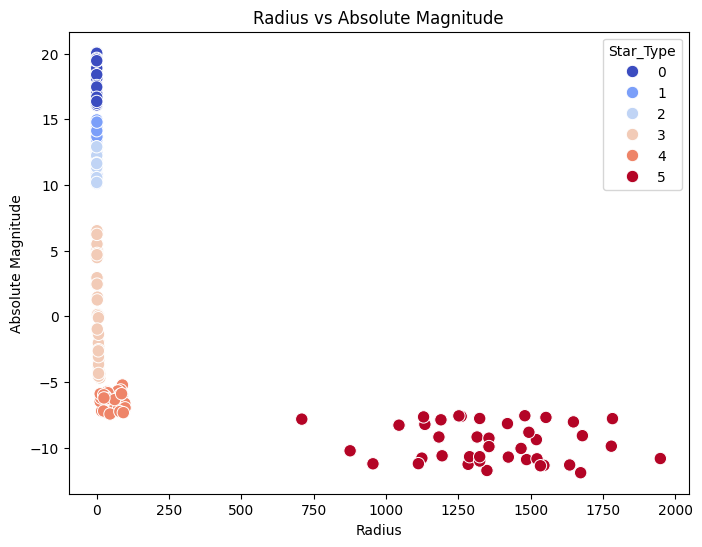

In [32]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='Radius',
    y='Absolute_Magnitude',
    hue='Star_Type',
    palette='coolwarm',
    s=80
)

plt.title("Radius vs Absolute Magnitude")
plt.xlabel("Radius")
plt.ylabel("Absolute Magnitude")
plt.show()

#STEP 8 Multivariate Analysis

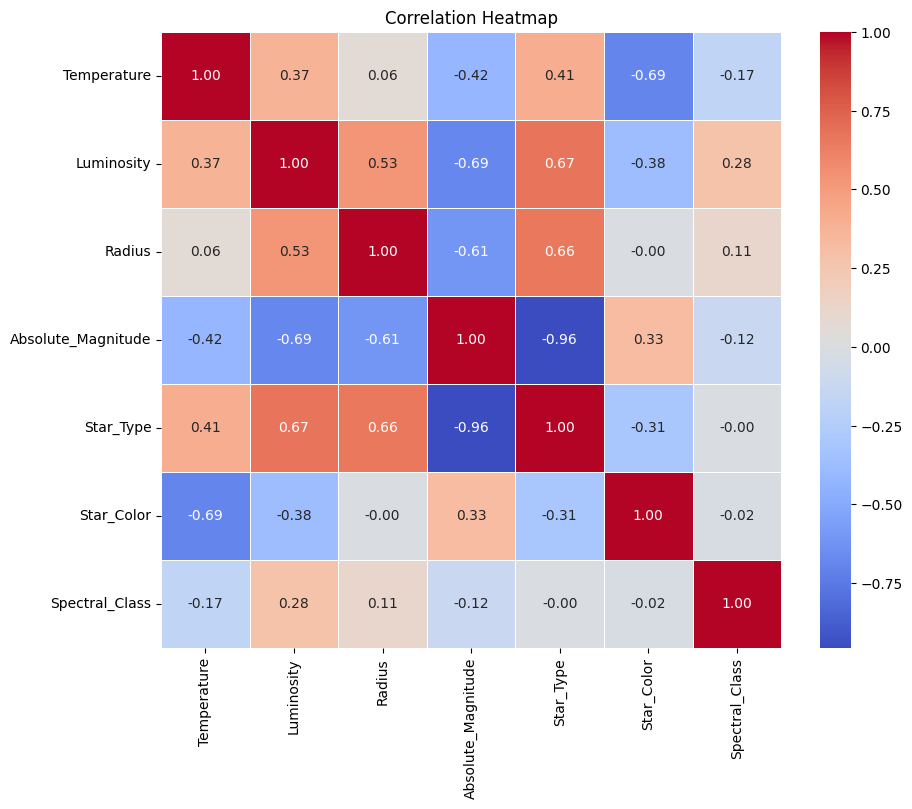

In [33]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

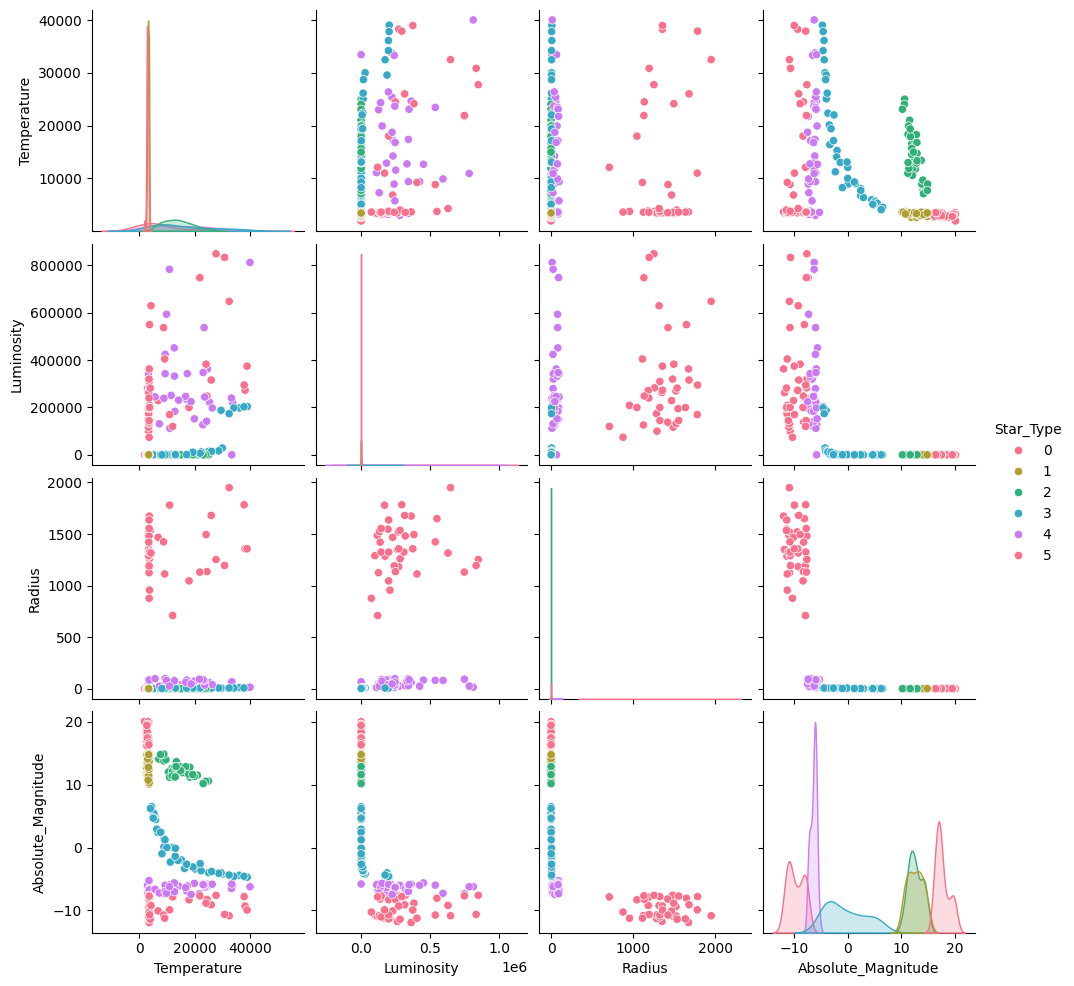

In [34]:
sns.pairplot(
    df,
    vars=['Temperature','Luminosity','Radius','Absolute_Magnitude'],
    hue='Star_Type',
    palette='husl'
)

plt.show()

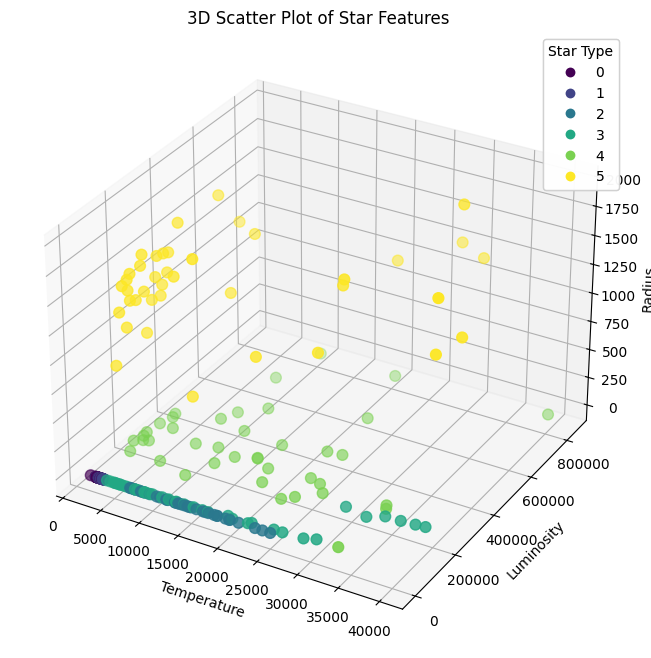

In [35]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df['Temperature'],
    df['Luminosity'],
    df['Radius'],
    c=df['Star_Type'],
    cmap='viridis',
    s=60
)

ax.set_xlabel("Temperature")
ax.set_ylabel("Luminosity")
ax.set_zlabel("Radius")

plt.title("3D Scatter Plot of Star Features")

legend = ax.legend(*scatter.legend_elements(), title="Star Type")
ax.add_artist(legend)

plt.show()